# Сравнение обученных моделей

Пять сохранённых состояний модели: 40M/200k, 49M/100k, 49M/200k, 49M/300k, 49M/400k. В первой части — обучение, во второй — индивидуальные профили, в третьей — сопоставление на одинаковых заданиях.

In [1]:
123

123

In [2]:
from pathlib import Path
import json
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator
from IPython.display import display, Markdown

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
DATA = ROOT / "data/evaluation/ggpt_v3"
EXPORT = ROOT / "reports/comparison"
MODELS = ["40m_200k", "49m_100k", "49m_200k", "49m_300k", "49m_400k"]
LABELS = {m: m.replace("m_", "M / ").replace("k", "k") for m in MODELS}
STAGES = {"40M": ["40m_v1", "40m_extended"], "49M": ["49m_v1", "49m_extended", "49m_300k", "49m_400k"]}
MODES = ["greedy", "topk_t08", "topp_t08", "conservative", "diverse"]
pd.set_option("display.max_colwidth", 110)
plt.rcParams.update({"figure.figsize": (9, 4.3), "axes.grid": True, "grid.alpha": .2})

def read_jsonl(path):
    with path.open(encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]

raw_scores = {m: read_jsonl(DATA / "benchmarks" / m / "scores.jsonl") for m in MODELS}
raw_gens = {m: read_jsonl(DATA / "benchmarks" / m / "generations.jsonl") for m in MODELS}
run_specs = {s: json.loads((DATA / "training" / s / "run_spec.json").read_text()) for stages in STAGES.values() for s in stages}
logs = []
for architecture, stages in STAGES.items():
    for stage in stages:
        for record in read_jsonl(DATA / "training" / stage / "metrics.jsonl"):
            logs.append({**record, "architecture": architecture, "stage": stage})
training = pd.DataFrame(logs)
training = training.sort_values("timestamp_utc").drop_duplicates(["architecture", "type", "step"], keep="last")
print("Исходные данные загружены:", {m: (len(raw_scores[m]), len(raw_gens[m])) for m in MODELS})

def format_step_ticks(ax):
    ax.xaxis.set_major_locator(MaxNLocator(nbins=5, integer=True))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x / 1000:g}k" if x else "0"))
    ax.tick_params(axis="x", labelsize=9)


Исходные данные загружены: {'40m_200k': (36, 270), '49m_100k': (36, 270), '49m_200k': (36, 270), '49m_300k': (36, 270), '49m_400k': (36, 270)}


## 1. Процесс обучения

### 1.1. Конфигурации и итоговые показатели

In [3]:
train = training[training.type == "train"].copy()
val = training[training.type == "val"].copy()
end_steps = {"40m_200k": 200000, "49m_100k": 100000, "49m_200k": 200000, "49m_300k": 300000, "49m_400k": 400000}
architecture_of = lambda m: "40M" if m.startswith("40") else "49M"
rows = []
for m in MODELS:
    arch, step = architecture_of(m), end_steps[m]
    v = val[(val.architecture == arch) & (val.step <= step)].sort_values("step").iloc[-1]
    r = run_specs[STAGES[arch][-1]]
    rows.append(dict(model=LABELS[m], steps=step, tokens=step * 8192,
                     layers=r["model"]["num_layers"], hidden=r["model"]["hidden_size"],
                     val_loss=v.loss, perplexity=v.perplexity))
training_summary = pd.DataFrame(rows)
display(training_summary.round(4))

,model,steps,tokens,layers,hidden,val_loss,perplexity
0,40M / 200k,200000,1638400000,10,512,3.3153,27.5296
1,49M / 100k,100000,819200000,12,512,3.3200,27.6602
2,49M / 200k,200000,1638400000,12,512,3.2365,25.4435
3,49M / 300k,300000,2457600000,12,512,3.2039,24.6291
4,49M / 400k,400000,3276800000,12,512,3.1903,24.2949


### 1.2. Динамика функции потерь и скорости обучения

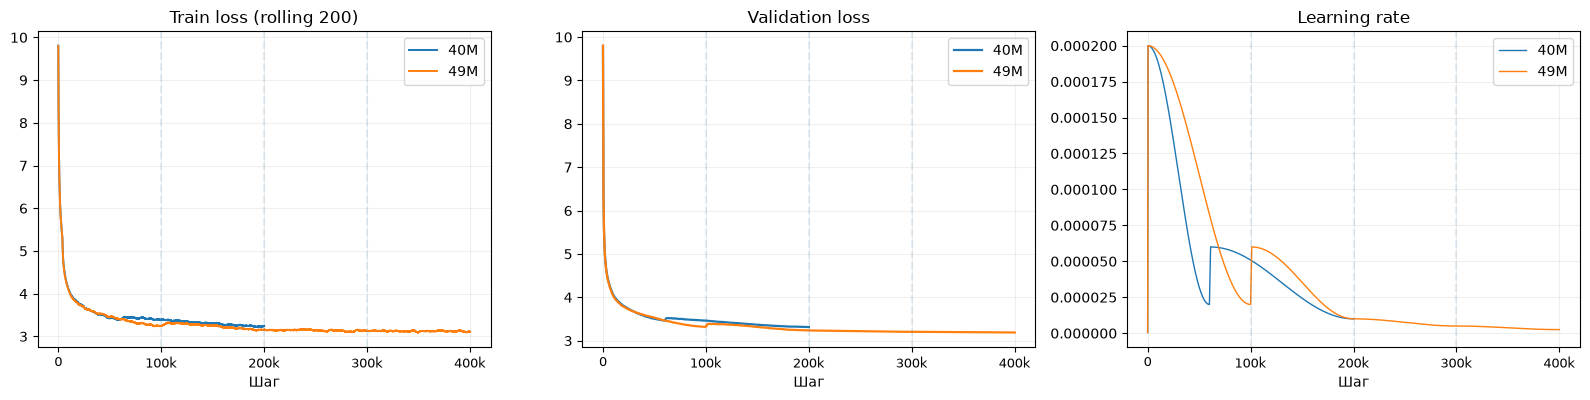

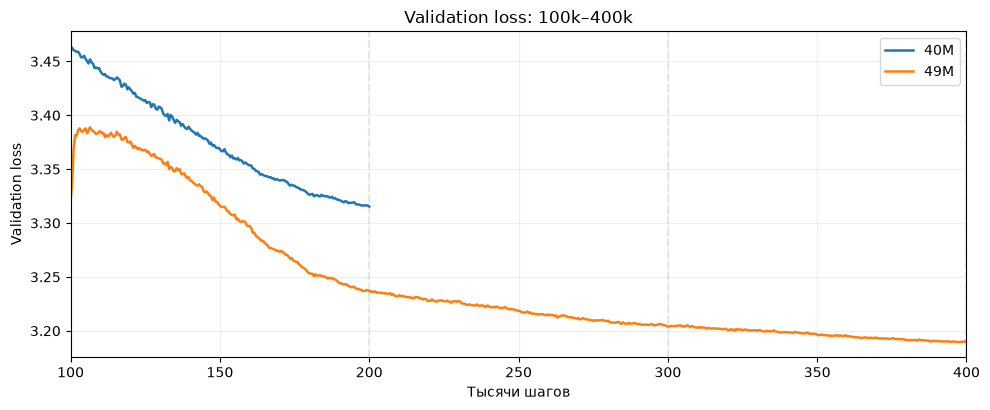

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.1))
for arch, group in train.groupby("architecture"):
    group = group.sort_values("step")
    axes[0].plot(group.step, group.loss.rolling(200, min_periods=1).mean(), label=arch, linewidth=1.4)
    axes[2].plot(group.step, group.lr, label=arch, linewidth=1)
for arch, group in val.groupby("architecture"):
    group = group.sort_values("step")
    axes[1].plot(group.step, group.loss, label=arch, linewidth=1.6)
for ax,title in zip(axes, ["Train loss (rolling 200)", "Validation loss", "Learning rate"]):
    ax.set(title=title, xlabel="Шаг")
    ax.legend()
for ax in axes:
    for s in [100000, 200000, 300000]:
        ax.axvline(s, alpha=.12, linestyle="--")
    format_step_ticks(ax)
plt.tight_layout();plt.show()

fig, ax = plt.subplots(figsize=(10, 4.2))
for arch, group in val.groupby("architecture"):
    late = group[group.step >= 100000].sort_values("step")
    ax.plot(late.step / 1000, late.loss, label=arch, linewidth=1.8)
for step in [100, 200, 300, 400]:
    ax.axvline(step, color="gray", alpha=.15, linestyle="--")
ax.set(title="Validation loss: 100k–400k", xlabel="Тысячи шагов", ylabel="Validation loss", xlim=(100, 400))
ax.set_xticks([100, 150, 200, 250, 300, 350, 400])
ax.legend()
plt.tight_layout(); plt.show()

### 1.3. Градиенты и вычислительные характеристики

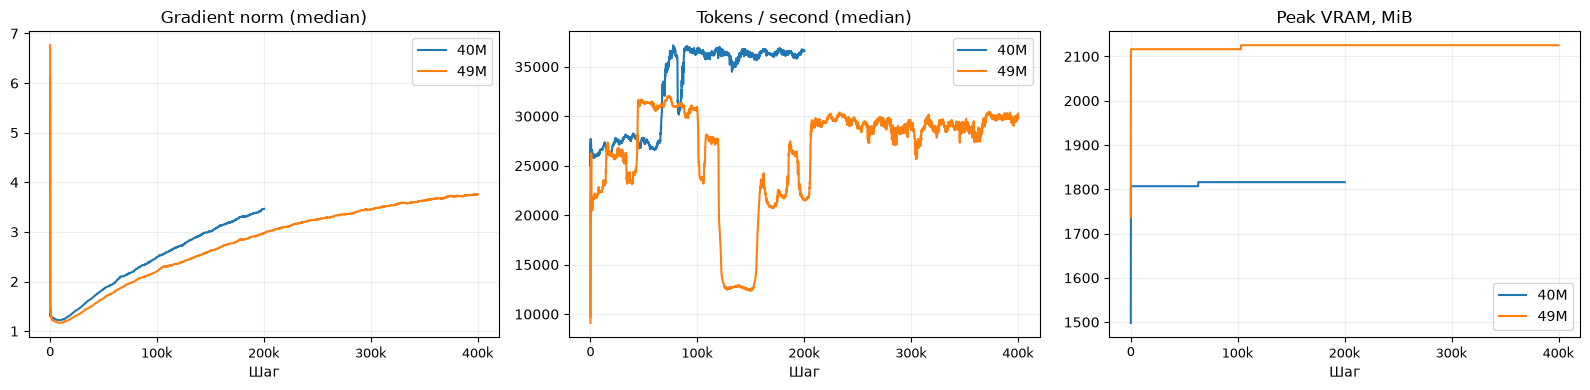

,model,steps,tokens,layers,hidden,val_loss,perplexity,delta_val_loss
0,40M / 200k,200000,1638400000,10,512,3.3153,27.5296,NaN
1,49M / 100k,100000,819200000,12,512,3.3200,27.6602,NaN
2,49M / 200k,200000,1638400000,12,512,3.2365,25.4435,-0.0835
3,49M / 300k,300000,2457600000,12,512,3.2039,24.6291,-0.0325
4,49M / 400k,400000,3276800000,12,512,3.1903,24.2949,-0.0137


In [5]:
fig,axes = plt.subplots(1,3,figsize=(16,4))
for arch,g in train.groupby("architecture"):
    g=g.sort_values("step")
    for ax,key in zip(axes,["grad_norm","tokens_per_second","peak_vram_mib"]):
        ax.plot(g.step, g[key].rolling(300,min_periods=1).median(),label=arch)
for ax,t in zip(axes,["Gradient norm (median)","Tokens / second (median)","Peak VRAM, MiB"]):
    ax.set(title=t,xlabel="Шаг")
    format_step_ticks(ax)
    ax.legend()
plt.tight_layout();plt.show()
display(training_summary.assign(delta_val_loss=training_summary.groupby(training_summary.model.str.extract(r"^(\d+M)")[0]).val_loss.diff()).round(4))

### 1.4. Анализ результатов обучения

Согласно таблице раздела 1.1 и кривым раздела 1.2, validation loss модели 49M последовательно снижался: с 3,3200 на 100 тыс. шагов до 3,1903 на 400 тыс.; perplexity уменьшилась с 27,66 до 24,29. Прирост между соседними стадиями постепенно сокращался: снижение loss составило соответственно 0,0835, 0,0325 и 0,0137. Такая динамика согласуется с замедлением улучшения предсказания по мере обучения.

При одинаковых 200 тыс. шагов модель 49M достигла меньшего validation loss, чем 40M: 3,2365 против 3,3153. В сравниваемых конфигурациях различается прежде всего глубина Transformer (12 и 10 слоёв при одинаковом hidden size 512).

## 2. Индивидуальные профили моделей

In [6]:
def score_frame(model):
    out=[]
    for r in raw_scores[model]:
        v=r["measurement"]
        candidates=v["candidates"]
        ref=v["reference"]
        scores=[c["log_probability"] for c in candidates]
        best_idx=int(np.argmax(scores))
        ctl=v.get("control")
        out.append(dict(model=model,id=r["id"],category=r["category"],format=r["format"],
                        prompt=r["prompt"],reference=ref["text"],best=candidates[best_idx]["text"],
                        rank_sum=v["reference_rank_by_sum"],top1=int(v["reference_rank_by_sum"]==1),
                        ref_logp=ref["log_probability"],
                        first_token_vocab_rank=ref["first_token_rank_vocab"],
                        margin=ref["log_probability"] - max((c["log_probability"] for c in candidates if c["text"] != ref["text"]),default=np.nan),
                        control_rank=ctl["reference_rank_by_sum"] if ctl else np.nan,
                        control_logp=ctl["reference"]["log_probability"] if ctl else np.nan,
                        control_top1=int(ctl["reference_rank_by_sum"]==1) if ctl else np.nan))
    return pd.DataFrame(out)
scores=pd.concat([score_frame(m) for m in MODELS],ignore_index=True)
scores["delta_logp"]=scores.ref_logp-scores.control_logp
scores["rank_gain"]=scores.control_rank-scores.rank_sum

def repeated_ngram_fraction(text,n=3):
    seq=re.findall(r"\w+",text.lower(),flags=re.UNICODE)
    gram=[tuple(seq[i:i+n]) for i in range(len(seq)-n+1)]
    return 1-len(set(gram))/len(gram) if gram else np.nan

def distinct_ngram(text,n=2):
    seq=re.findall(r"\w+",text.lower(),flags=re.UNICODE)
    gram=[tuple(seq[i:i+n]) for i in range(len(seq)-n+1)]
    return len(set(gram))/len(gram) if gram else np.nan

generations=pd.DataFrame([{**{k:r.get(k) for k in ("id","category","format","prompt","response","variant","reference")},"model":m} for m in MODELS for r in raw_gens[m]])
generations["word_count"]=generations.response.map(lambda t:len(re.findall(r"\w+",t)))
generations["char_count"]=generations.response.str.len()
generations["repeat_3gram"]=generations.response.map(repeated_ngram_fraction)
generations["distinct_2gram"]=generations.response.map(distinct_ngram)
continuations=generations[generations.category=="continuation"].copy()

judge_raw = read_jsonl(DATA / "judge/judgments.jsonl")
judge_rows = []
for record in judge_raw:
    judge_rows.append({
        **{k: record[k] for k in ("item_id", "model", "task_id", "variant", "overall", "reason_ru")},
        **{k: record["scores"][k] for k in ("beginning", "language", "topic_genre", "coherence", "stability")},
        "good_beginning": record["good_beginning"],
        "later_degradation": record["later_degradation"],
    })
judge = pd.DataFrame(judge_rows)
JUDGE_CRITERIA = ["beginning", "language", "topic_genre", "coherence", "stability"]
JUDGE_LABELS = ["Начало", "Язык", "Тема и жанр", "Связность", "Стабильность"]
JUDGE_CATEGORIES = ["Удачно", "Частично удачно", "Неудачно"]
judge["mean_score"] = judge[JUDGE_CRITERIA].mean(axis=1)
judge_counts = pd.crosstab(judge.model, judge.overall).reindex(index=MODELS, columns=JUDGE_CATEGORIES, fill_value=0)
judge_criteria = judge.groupby("model")[JUDGE_CRITERIA].mean().reindex(MODELS)
judge_examples = json.loads((DATA / "judge/examples.json").read_text(encoding="utf-8"))


def show_quality_examples(model):
    from html import escape
    from IPython.display import HTML

    selected = [example for example in judge_examples if example["model"] == model]
    display(Markdown("**Примеры лучших продолжений с переводом на русский**"))
    for example in selected:
        row = judge[judge.item_id == example["item_id"]].iloc[0]
        source = continuations[
            (continuations.model == model)
            & (continuations.id == example["task_id"])
            & (continuations.variant == example["variant"])
        ].iloc[0]
        meta = f'{row.overall} · {example["task_id"]} · {example["variant"]}'
        note = "" if row.overall == "Удачно" else "<div style='margin-top:.4em'><em>Оценка судьи: " + escape(str(row.reason_ru)) + "</em></div>"
        html = (
            "<div style='margin:.8em 0 1.2em; padding:.7em 1em; border-left:2px solid #888'>"
            "<div><strong>" + escape(meta) + "</strong></div>"
            "<div style='white-space:pre-wrap; margin-top:.45em'>" + escape(example["excerpt"]) + "</div>"
            "<div style='white-space:pre-wrap; margin-top:.5em; opacity:.8'><em>Перевод:</em> "
            + escape(example["translation"]) + "</div>" + note
            + "<details style='margin-top:.5em'><summary>Промпт и полное продолжение</summary>"
            + "<div style='white-space:pre-wrap; margin-top:.35em'><b>Промпт:</b> " + escape(source.prompt)
            + "</div><div style='white-space:pre-wrap; margin-top:.35em'><b>Продолжение:</b> "
            + escape(source.response) + "</div></details></div>"
        )
        display(HTML(html))

def profile(model):
    section = f"2.{MODELS.index(model) + 1}"
    s=scores[scores.model==model]
    facts=s[s.category=="facts"]
    context=s[s.category=="context"]
    display(Markdown(f"#### {section}.1. Фактические знания"))
    display(pd.DataFrame([dict(questions=len(facts),top1=int(facts.top1.sum()),mean_rank=facts.rank_sum.mean())]).round(3))
    display(facts[["id","prompt","reference","best","rank_sum","first_token_vocab_rank","margin"]].round(3))
    display(Markdown(f"#### {section}.2. Использование контекста"))
    display(context.groupby("format").agg(tasks=("id","size"),top1=("top1","sum"),control_top1=("control_top1","sum"),mean_rank=("rank_sum","mean"),mean_rank_gain=("rank_gain","mean"),mean_delta_logp=("delta_logp","mean")).round(3))
    display(context[["id","prompt","reference","best","rank_sum","control_rank","rank_gain","delta_logp"]].round(3))
    display(Markdown(f"#### {section}.3. Свободная генерация: 18 промптов × 5 режимов"))
    g=continuations[continuations.model==model]
    display(g.groupby("variant").agg(texts=("id","size"),mean_words=("word_count","mean"),repeat_3gram=("repeat_3gram","mean"),distinct_2gram=("distinct_2gram","mean")).reindex(MODES).round(3))
    fig,axes=plt.subplots(1,2,figsize=(10,3.6))
    for ax,col in zip(axes,["repeat_3gram","distinct_2gram"]):
        series = [g.loc[g.variant == mode, col].dropna() for mode in MODES]
        ax.boxplot(series)
        ax.set_xticks(range(1, 6))
        ax.set_xticklabels(["Greedy", "Top-k", "Top-p", "Cons.", "Diverse"])
        ax.set(xlabel="Режим", ylabel=col, title=col)
        ax.tick_params(axis="x", labelsize=8)
    fig.suptitle("");plt.tight_layout();plt.show()
    display(Markdown(f"#### {section}.4. Качественная оценка генерации"))
    local = judge[judge.model == model]
    counts = judge_counts.loc[model].to_frame("Продолжений").T
    display(counts)
    criteria = judge_criteria.loc[model]
    display(pd.DataFrame([criteria.to_numpy()], columns=JUDGE_LABELS, index=["Средняя оценка (0–2)"]).round(2))
    show_quality_examples(model)

### 2.1. 40M / 200k — индивидуальная оценка

#### 2.1.1. Фактические знания

,questions,top1,mean_rank
0,18,7,1.833


,id,prompt,reference,best,rank_sum,first_token_vocab_rank,margin
0,fact_capital,საქართველოს დედაქალაქია,თბილისი,თბილისი,1,5,0.753
1,fact_currency,საქართველოს ეროვნული ვალუტაა,ლარი,ევრო,2,43,-0.092
2,fact_language,საქართველოს სახელმწიფო ენაა,ქართული,ინგლისური,2,7,-0.243
3,fact_sea,საქართველოს დასავლეთ სანაპიროს ესაზღვრება,შავი ზღვა,შავი ზღვა,1,20,1.042
4,fact_river,თბილისში მიედინება მდინარე,მტკვარი,მტკვარი,1,1,1.936
5,fact_adjara_center,აჭარის ავტონომიური რესპუბლიკის ადმინისტრაციული ცენტრია,ბათუმი,ბათუმი,1,114,0.934
6,fact_imereti_center,იმერეთის მხარის ადმინისტრაციული ცენტრია,ქუთაისი,გორი,3,166,-0.124
7,fact_kakheti_center,კახეთის მხარის ადმინისტრაციული ცენტრია,თელავი,თელავი,1,12,2.063
8,fact_samegrelo_center,სამეგრელო-ზემო სვანეთის მხარის ადმინისტრაციული ცენტრია,ზუგდიდი,ქუთაისი,2,158,-0.314
9,fact_rustaveli,პოემა „ვეფხისტყაოსნის“ ავტორია,შოთა რუსთაველი,ილია ჭავჭავაძე,2,61,-2.132


#### 2.1.2. Использование контекста

,tasks,top1,control_top1,mean_rank,mean_rank_gain,mean_delta_logp
format,,,,,,
cloze,12,3,1.0,2.0,0.917,3.820
qa,6,2,1.0,2.0,1.000,2.873


,id,prompt,reference,best,rank_sum,control_rank,rank_gain,delta_logp
18,ctx_commute,"ნინო ცხოვრობს ბათუმში, მაგრამ მუშაობს ქუთაისში. ის ყოველდღე დილით სამსახურში მიდის. დღესაც ავტობუსით გაემგ...",ქუთაისში,ბათუმში,2,3.0,1.0,4.800
19,ctx_package,"ლევანმა წითელ ყუთში ჩადო წიგნი, ხოლო ლურჯ ყუთში — გასაღები. შემდეგ მას გასაღები დასჭირდა. მან გახსნა",ლურჯი ყუთი,წითელი ყუთი,3,4.0,1.0,2.773
20,ctx_favorite,"მარიამს უყვარს მწვანე ჩაი, მის ძმას კი შავი ჩაი. სტუმარმა მარიამისთვის სასმელი მოამზადა. მან აადუღა წყალი ...",მწვანე ჩაი,მწვანე ჩაი,1,2.0,1.0,3.241
21,ctx_school,"დათო სწავლობს სკოლა ნომერ 18-ში, მისი მეგობარი კი სკოლა ნომერ 27-ში. დღეს დათო საკუთარ სკოლაში მიდის. დათო...",18,12,2,2.0,0.0,1.176
22,ctx_meeting_day,"შეხვედრა თავიდან სამშაბათს იყო დაგეგმილი, მაგრამ შემდეგ ხუთშაბათზე გადაიტანეს. საბოლოოდ შეხვედრა გაიმართება",ხუთშაბათს,ორშაბათს,3,2.0,-1.0,0.882
23,ctx_blue_book,"ანა მაგიდაზე დადებულ ორ წიგნს არჩევდა. ისტორიის წიგნი ლურჯი იყო, მათემატიკისა — ყვითელი. ანამ ისტორიის წიგ...",ლურჯი,წითელი,2,3.0,1.0,2.557
24,ctx_weather_city,"დღეს გორში თოვს, ხოლო ფოთში წვიმს. რეზო ფოთში იმყოფება და ქუჩაში გავიდა. მისი ქალაქის ამინდია",წვიმა,წვიმა,1,1.0,0.0,1.171
25,ctx_trip_destination,"მოგზაურები თავდაპირველად თელავში აპირებდნენ წასვლას, მაგრამ საბოლოოდ სიღნაღი აირჩიეს. ისინი მანქანით გაემგ...",სიღნაღში,თელავში,2,4.0,2.0,3.950
26,ctx_pet_name,"თამარის ძაღლს ბუბუ ჰქვია, ხოლო კატის სახელია ციცო. ეზოში თამარმა ძაღლს დაუძახა. მან ხმამაღლა თქვა",ბუბუ,ბუბუ,1,4.0,3.0,10.585
27,ctx_purchase,"გიორგის სამი ვაშლი და ორი მსხალი ჰქონდა. მან ყველა ვაშლი მეგობარს მისცა, მსხალი კი თავისთვის დატოვა. გიორგ...",ორი მსხალი,სამი ვაშლი,3,4.0,1.0,3.810


#### 2.1.3. Свободная генерация: 18 промптов × 5 режимов

,texts,mean_words,repeat_3gram,distinct_2gram
variant,,,,
greedy,18,51.611,0.605,0.352
topk_t08,18,52.944,0.017,0.939
topp_t08,18,49.278,0.028,0.940
conservative,18,48.778,0.203,0.729
diverse,18,47.778,0.000,0.996


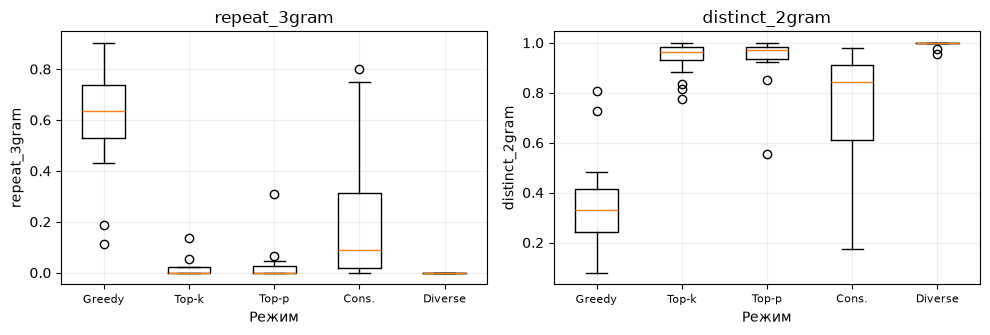

#### 2.1.4. Качественная оценка генерации

overall,Удачно,Частично удачно,Неудачно
Продолжений,0,19,71


,Начало,Язык,Тема и жанр,Связность,Стабильность
Средняя оценка (0–2),0.61,0.89,0.98,0.13,0.29


**Примеры лучших продолжений с переводом на русский**

In [7]:
profile("40m_200k")

#### 2.1.5. Анализ результатов

По результатам раздела 2.1, модель 40M/200k верно ранжировала эталонный ответ первым в 7 из 18 заданий на факты. В задачах с контекстом результат составил 5 из 18 против 2 из 18 без контекста; среднее улучшение ранга — 0,94 позиции. Это наибольшее улучшение ранга в данной группе моделей, однако абсолютная доля правильных ответов остаётся невысокой. Такой результат указывает на чувствительность к дополнительной информации, но не позволяет говорить об устойчивом использовании контекста.

Качественная оценка свободных продолжений значительно слабее: 19 из 90 признаны частично удачными, полностью удачных нет, средний балл критериев — 0,58 из 2. Особенно низки связность (0,13) и стабильность (0,29). Примеры из раздела 2.1.4 показывают, что грамматически приемлемый фрагмент может быстро сменяться повторениями или потерей смысловой линии. Ограничение скорее связано с удержанием связного текста, чем с полным отсутствием локальных языковых закономерностей.

### 2.2. 49M / 100k — индивидуальная оценка

#### 2.2.1. Фактические знания

,questions,top1,mean_rank
0,18,9,1.611


,id,prompt,reference,best,rank_sum,first_token_vocab_rank,margin
36,fact_capital,საქართველოს დედაქალაქია,თბილისი,თბილისი,1,2,2.430
37,fact_currency,საქართველოს ეროვნული ვალუტაა,ლარი,ევრო,2,15,-0.969
38,fact_language,საქართველოს სახელმწიფო ენაა,ქართული,ქართული,1,5,1.491
39,fact_sea,საქართველოს დასავლეთ სანაპიროს ესაზღვრება,შავი ზღვა,შავი ზღვა,1,7,1.184
40,fact_river,თბილისში მიედინება მდინარე,მტკვარი,მტკვარი,1,1,2.510
41,fact_adjara_center,აჭარის ავტონომიური რესპუბლიკის ადმინისტრაციული ცენტრია,ბათუმი,ბათუმი,1,6,2.221
42,fact_imereti_center,იმერეთის მხარის ადმინისტრაციული ცენტრია,ქუთაისი,ქუთაისი,1,14,1.782
43,fact_kakheti_center,კახეთის მხარის ადმინისტრაციული ცენტრია,თელავი,თელავი,1,3,1.828
44,fact_samegrelo_center,სამეგრელო-ზემო სვანეთის მხარის ადმინისტრაციული ცენტრია,ზუგდიდი,ზუგდიდი,1,12,0.140
45,fact_rustaveli,პოემა „ვეფხისტყაოსნის“ ავტორია,შოთა რუსთაველი,აკაკი წერეთელი,3,10,-1.795


#### 2.2.2. Использование контекста

,tasks,top1,control_top1,mean_rank,mean_rank_gain,mean_delta_logp
format,,,,,,
cloze,12,2,1.0,2.333,0.417,3.910
qa,6,1,1.0,2.833,0.167,2.438


,id,prompt,reference,best,rank_sum,control_rank,rank_gain,delta_logp
54,ctx_commute,"ნინო ცხოვრობს ბათუმში, მაგრამ მუშაობს ქუთაისში. ის ყოველდღე დილით სამსახურში მიდის. დღესაც ავტობუსით გაემგ...",ქუთაისში,ბათუმში,3,3.0,0.0,3.594
55,ctx_package,"ლევანმა წითელ ყუთში ჩადო წიგნი, ხოლო ლურჯ ყუთში — გასაღები. შემდეგ მას გასაღები დასჭირდა. მან გახსნა",ლურჯი ყუთი,წითელი ყუთი,3,3.0,0.0,2.796
56,ctx_favorite,"მარიამს უყვარს მწვანე ჩაი, მის ძმას კი შავი ჩაი. სტუმარმა მარიამისთვის სასმელი მოამზადა. მან აადუღა წყალი ...",მწვანე ჩაი,მწვანე ჩაი,1,2.0,1.0,3.769
57,ctx_school,"დათო სწავლობს სკოლა ნომერ 18-ში, მისი მეგობარი კი სკოლა ნომერ 27-ში. დღეს დათო საკუთარ სკოლაში მიდის. დათო...",18,18,1,1.0,0.0,2.926
58,ctx_meeting_day,"შეხვედრა თავიდან სამშაბათს იყო დაგეგმილი, მაგრამ შემდეგ ხუთშაბათზე გადაიტანეს. საბოლოოდ შეხვედრა გაიმართება",ხუთშაბათს,ორშაბათს,2,2.0,0.0,1.860
59,ctx_blue_book,"ანა მაგიდაზე დადებულ ორ წიგნს არჩევდა. ისტორიის წიგნი ლურჯი იყო, მათემატიკისა — ყვითელი. ანამ ისტორიის წიგ...",ლურჯი,წითელი,2,2.0,0.0,3.229
60,ctx_weather_city,"დღეს გორში თოვს, ხოლო ფოთში წვიმს. რეზო ფოთში იმყოფება და ქუჩაში გავიდა. მისი ქალაქის ამინდია",წვიმა,თოვლი,3,3.0,0.0,1.140
61,ctx_trip_destination,"მოგზაურები თავდაპირველად თელავში აპირებდნენ წასვლას, მაგრამ საბოლოოდ სიღნაღი აირჩიეს. ისინი მანქანით გაემგ...",სიღნაღში,თელავში,3,3.0,0.0,3.423
62,ctx_pet_name,"თამარის ძაღლს ბუბუ ჰქვია, ხოლო კატის სახელია ციცო. ეზოში თამარმა ძაღლს დაუძახა. მან ხმამაღლა თქვა",ბუბუ,ციცო,2,4.0,2.0,9.455
63,ctx_purchase,"გიორგის სამი ვაშლი და ორი მსხალი ჰქონდა. მან ყველა ვაშლი მეგობარს მისცა, მსხალი კი თავისთვის დატოვა. გიორგ...",ორი მსხალი,სამი ვაშლი,2,4.0,2.0,8.171


#### 2.2.3. Свободная генерация: 18 промптов × 5 режимов

,texts,mean_words,repeat_3gram,distinct_2gram
variant,,,,
greedy,18,54.833,0.661,0.297
topk_t08,18,48.278,0.026,0.934
topp_t08,18,52.222,0.007,0.971
conservative,18,50.611,0.104,0.824
diverse,18,48.778,0.000,0.999


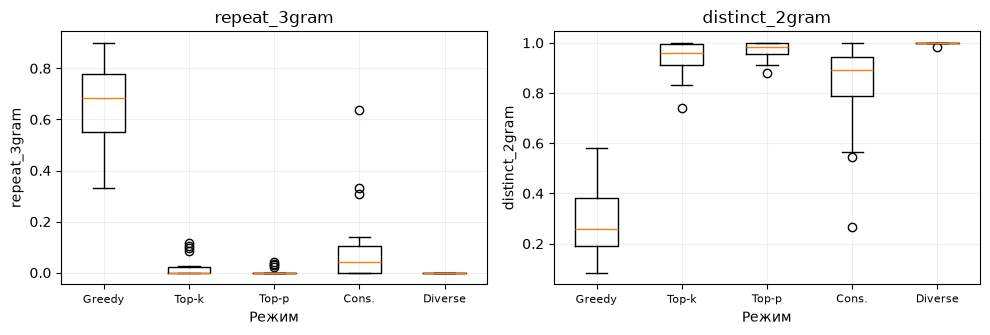

#### 2.2.4. Качественная оценка генерации

overall,Удачно,Частично удачно,Неудачно
Продолжений,2,23,65


,Начало,Язык,Тема и жанр,Связность,Стабильность
Средняя оценка (0–2),0.67,0.89,1.02,0.2,0.33


**Примеры лучших продолжений с переводом на русский**

In [8]:
profile("49m_100k")

#### 2.2.5. Анализ результатов

На 100 тыс. шагов модель 49M получила 9 из 18 правильных первых мест в фактических заданиях и 3 из 18 в задачах с контекстом. По сравнению с 40M/200k фактический результат выше, однако различаются как архитектура, так и длительность обучения, поэтому прямое объяснение разницы числом параметров некорректно.

По оценкам судьи 2 из 90 продолжений признаны удачными, 23 — частично удачными, 65 — неудачными; средний балл равен 0,62. Начало и тематическое соответствие оцениваются выше связности и стабильности. Такая структура результатов согласуется с ранней стадией формирования устойчивых локальных языковых шаблонов: отдельные предложения выглядят естественно, но их последовательное объединение в текст остаётся затруднительным.

### 2.3. 49M / 200k — индивидуальная оценка

#### 2.3.1. Фактические знания

,questions,top1,mean_rank
0,18,13,1.444


,id,prompt,reference,best,rank_sum,first_token_vocab_rank,margin
72,fact_capital,საქართველოს დედაქალაქია,თბილისი,თბილისი,1,1,2.546
73,fact_currency,საქართველოს ეროვნული ვალუტაა,ლარი,ლარი,1,8,0.719
74,fact_language,საქართველოს სახელმწიფო ენაა,ქართული,ქართული,1,5,2.195
75,fact_sea,საქართველოს დასავლეთ სანაპიროს ესაზღვრება,შავი ზღვა,შავი ზღვა,1,1,0.958
76,fact_river,თბილისში მიედინება მდინარე,მტკვარი,მტკვარი,1,1,2.522
77,fact_adjara_center,აჭარის ავტონომიური რესპუბლიკის ადმინისტრაციული ცენტრია,ბათუმი,ბათუმი,1,5,3.471
78,fact_imereti_center,იმერეთის მხარის ადმინისტრაციული ცენტრია,ქუთაისი,ქუთაისი,1,12,2.221
79,fact_kakheti_center,კახეთის მხარის ადმინისტრაციული ცენტრია,თელავი,თელავი,1,6,3.443
80,fact_samegrelo_center,სამეგრელო-ზემო სვანეთის მხარის ადმინისტრაციული ცენტრია,ზუგდიდი,ზუგდიდი,1,21,1.280
81,fact_rustaveli,პოემა „ვეფხისტყაოსნის“ ავტორია,შოთა რუსთაველი,შოთა რუსთაველი,1,12,0.133


#### 2.3.2. Использование контекста

,tasks,top1,control_top1,mean_rank,mean_rank_gain,mean_delta_logp
format,,,,,,
cloze,12,3,1.0,2.250,0.333,4.206
qa,6,1,1.0,2.667,0.333,2.496


,id,prompt,reference,best,rank_sum,control_rank,rank_gain,delta_logp
90,ctx_commute,"ნინო ცხოვრობს ბათუმში, მაგრამ მუშაობს ქუთაისში. ის ყოველდღე დილით სამსახურში მიდის. დღესაც ავტობუსით გაემგ...",ქუთაისში,ბათუმში,3,3.0,0.0,4.291
91,ctx_package,"ლევანმა წითელ ყუთში ჩადო წიგნი, ხოლო ლურჯ ყუთში — გასაღები. შემდეგ მას გასაღები დასჭირდა. მან გახსნა",ლურჯი ყუთი,წითელი ყუთი,3,2.0,-1.0,2.733
92,ctx_favorite,"მარიამს უყვარს მწვანე ჩაი, მის ძმას კი შავი ჩაი. სტუმარმა მარიამისთვის სასმელი მოამზადა. მან აადუღა წყალი ...",მწვანე ჩაი,მწვანე ჩაი,1,2.0,1.0,3.508
93,ctx_school,"დათო სწავლობს სკოლა ნომერ 18-ში, მისი მეგობარი კი სკოლა ნომერ 27-ში. დღეს დათო საკუთარ სკოლაში მიდის. დათო...",18,18,1,1.0,0.0,3.378
94,ctx_meeting_day,"შეხვედრა თავიდან სამშაბათს იყო დაგეგმილი, მაგრამ შემდეგ ხუთშაბათზე გადაიტანეს. საბოლოოდ შეხვედრა გაიმართება",ხუთშაბათს,ორშაბათს,3,2.0,-1.0,2.070
95,ctx_blue_book,"ანა მაგიდაზე დადებულ ორ წიგნს არჩევდა. ისტორიის წიგნი ლურჯი იყო, მათემატიკისა — ყვითელი. ანამ ისტორიის წიგ...",ლურჯი,ლურჯი,1,2.0,1.0,3.211
96,ctx_weather_city,"დღეს გორში თოვს, ხოლო ფოთში წვიმს. რეზო ფოთში იმყოფება და ქუჩაში გავიდა. მისი ქალაქის ამინდია",წვიმა,ნისლი,3,3.0,0.0,1.762
97,ctx_trip_destination,"მოგზაურები თავდაპირველად თელავში აპირებდნენ წასვლას, მაგრამ საბოლოოდ სიღნაღი აირჩიეს. ისინი მანქანით გაემგ...",სიღნაღში,თელავში,2,4.0,2.0,3.796
98,ctx_pet_name,"თამარის ძაღლს ბუბუ ჰქვია, ხოლო კატის სახელია ციცო. ეზოში თამარმა ძაღლს დაუძახა. მან ხმამაღლა თქვა",ბუბუ,ციცო,2,4.0,2.0,10.018
99,ctx_purchase,"გიორგის სამი ვაშლი და ორი მსხალი ჰქონდა. მან ყველა ვაშლი მეგობარს მისცა, მსხალი კი თავისთვის დატოვა. გიორგ...",ორი მსხალი,სამი ვაშლი,2,2.0,0.0,6.774


#### 2.3.3. Свободная генерация: 18 промптов × 5 режимов

,texts,mean_words,repeat_3gram,distinct_2gram
variant,,,,
greedy,18,50.667,0.601,0.366
topk_t08,18,46.944,0.030,0.930
topp_t08,18,51.611,0.009,0.966
conservative,18,52.111,0.175,0.758
diverse,18,47.611,0.000,0.999


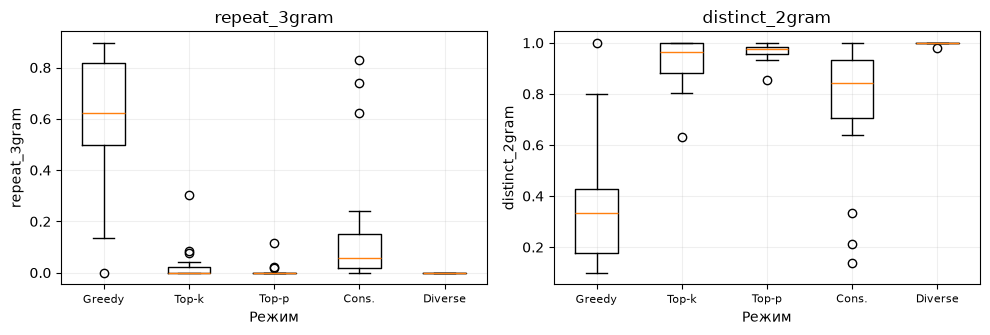

#### 2.3.4. Качественная оценка генерации

overall,Удачно,Частично удачно,Неудачно
Продолжений,4,16,70


,Начало,Язык,Тема и жанр,Связность,Стабильность
Средняя оценка (0–2),0.7,0.98,1.0,0.23,0.33


**Примеры лучших продолжений с переводом на русский**

In [9]:
profile("49m_200k")

#### 2.3.5. Анализ результатов

При увеличении обучения до 200 тыс. шагов результат по фактам вырос до 13 из 18, а средний ранг эталона снизился до 1,44 (раздел 2.3.1). По контекстным заданиям первое место достигнуто в 4 случаях из 18. Таким образом, улучшение предсказания типичных фактических продолжений заметнее, чем способность стабильно извлекать сведения из нового контекста.

Среди 90 свободных продолжений зафиксированы 4 удачных — максимум среди пяти checkpoint, но ещё 70 признаны неудачными. Средний балл судьи составил 0,65, что ниже результата 49M/300k. На этой стадии расширение обучения, вероятно, позволило закрепить некоторые частотные конструкции, не устранив склонность к распаду длинного продолжения.

### 2.4. 49M / 300k — индивидуальная оценка

#### 2.4.1. Фактические знания

,questions,top1,mean_rank
0,18,12,1.556


,id,prompt,reference,best,rank_sum,first_token_vocab_rank,margin
108,fact_capital,საქართველოს დედაქალაქია,თბილისი,თბილისი,1,1,3.037
109,fact_currency,საქართველოს ეროვნული ვალუტაა,ლარი,ლარი,1,3,0.679
110,fact_language,საქართველოს სახელმწიფო ენაა,ქართული,ქართული,1,4,1.965
111,fact_sea,საქართველოს დასავლეთ სანაპიროს ესაზღვრება,შავი ზღვა,შავი ზღვა,1,2,1.072
112,fact_river,თბილისში მიედინება მდინარე,მტკვარი,მტკვარი,1,1,4.057
113,fact_adjara_center,აჭარის ავტონომიური რესპუბლიკის ადმინისტრაციული ცენტრია,ბათუმი,ბათუმი,1,10,3.570
114,fact_imereti_center,იმერეთის მხარის ადმინისტრაციული ცენტრია,ქუთაისი,ქუთაისი,1,17,1.943
115,fact_kakheti_center,კახეთის მხარის ადმინისტრაციული ცენტრია,თელავი,თელავი,1,6,3.624
116,fact_samegrelo_center,სამეგრელო-ზემო სვანეთის მხარის ადმინისტრაციული ცენტრია,ზუგდიდი,ზუგდიდი,1,67,0.154
117,fact_rustaveli,პოემა „ვეფხისტყაოსნის“ ავტორია,შოთა რუსთაველი,ილია ჭავჭავაძე,2,20,-0.278


#### 2.4.2. Использование контекста

,tasks,top1,control_top1,mean_rank,mean_rank_gain,mean_delta_logp
format,,,,,,
cloze,12,3,2.0,2.333,0.333,3.871
qa,6,1,1.0,2.667,0.500,3.182


,id,prompt,reference,best,rank_sum,control_rank,rank_gain,delta_logp
126,ctx_commute,"ნინო ცხოვრობს ბათუმში, მაგრამ მუშაობს ქუთაისში. ის ყოველდღე დილით სამსახურში მიდის. დღესაც ავტობუსით გაემგ...",ქუთაისში,ბათუმში,3,3.0,0.0,3.134
127,ctx_package,"ლევანმა წითელ ყუთში ჩადო წიგნი, ხოლო ლურჯ ყუთში — გასაღები. შემდეგ მას გასაღები დასჭირდა. მან გახსნა",ლურჯი ყუთი,წითელი ყუთი,3,3.0,0.0,2.820
128,ctx_favorite,"მარიამს უყვარს მწვანე ჩაი, მის ძმას კი შავი ჩაი. სტუმარმა მარიამისთვის სასმელი მოამზადა. მან აადუღა წყალი ...",მწვანე ჩაი,მწვანე ჩაი,1,2.0,1.0,2.793
129,ctx_school,"დათო სწავლობს სკოლა ნომერ 18-ში, მისი მეგობარი კი სკოლა ნომერ 27-ში. დღეს დათო საკუთარ სკოლაში მიდის. დათო...",18,18,1,1.0,0.0,2.529
130,ctx_meeting_day,"შეხვედრა თავიდან სამშაბათს იყო დაგეგმილი, მაგრამ შემდეგ ხუთშაბათზე გადაიტანეს. საბოლოოდ შეხვედრა გაიმართება",ხუთშაბათს,ორშაბათს,3,2.0,-1.0,1.694
131,ctx_blue_book,"ანა მაგიდაზე დადებულ ორ წიგნს არჩევდა. ისტორიის წიგნი ლურჯი იყო, მათემატიკისა — ყვითელი. ანამ ისტორიის წიგ...",ლურჯი,წითელი,2,3.0,1.0,3.161
132,ctx_weather_city,"დღეს გორში თოვს, ხოლო ფოთში წვიმს. რეზო ფოთში იმყოფება და ქუჩაში გავიდა. მისი ქალაქის ამინდია",წვიმა,ნისლი,3,3.0,0.0,1.677
133,ctx_trip_destination,"მოგზაურები თავდაპირველად თელავში აპირებდნენ წასვლას, მაგრამ საბოლოოდ სიღნაღი აირჩიეს. ისინი მანქანით გაემგ...",სიღნაღში,თელავში,3,4.0,1.0,3.469
134,ctx_pet_name,"თამარის ძაღლს ბუბუ ჰქვია, ხოლო კატის სახელია ციცო. ეზოში თამარმა ძაღლს დაუძახა. მან ხმამაღლა თქვა",ბუბუ,ბუბუ,1,4.0,3.0,9.787
135,ctx_purchase,"გიორგის სამი ვაშლი და ორი მსხალი ჰქონდა. მან ყველა ვაშლი მეგობარს მისცა, მსხალი კი თავისთვის დატოვა. გიორგ...",ორი მსხალი,სამი ვაშლი,2,2.0,0.0,6.600


#### 2.4.3. Свободная генерация: 18 промптов × 5 режимов

,texts,mean_words,repeat_3gram,distinct_2gram
variant,,,,
greedy,18,49.111,0.640,0.329
topk_t08,18,51.278,0.030,0.918
topp_t08,18,50.778,0.015,0.956
conservative,18,51.500,0.151,0.783
diverse,18,43.667,0.008,0.989


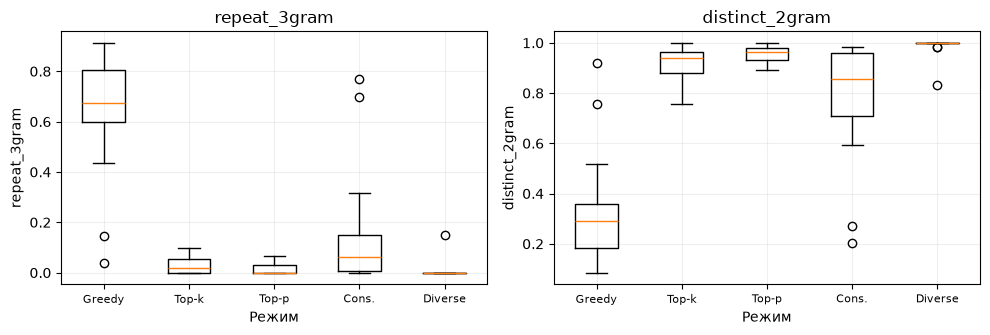

#### 2.4.4. Качественная оценка генерации

overall,Удачно,Частично удачно,Неудачно
Продолжений,2,26,62


,Начало,Язык,Тема и жанр,Связность,Стабильность
Средняя оценка (0–2),0.86,1.06,1.08,0.24,0.42


**Примеры лучших продолжений с переводом на русский**

In [10]:
profile("49m_300k")

#### 2.4.5. Анализ результатов

Модель 49M/300k получила 12 из 18 первых мест в заданиях на факты и 4 из 18 в задачах с контекстом. Относительно 200k эти показатели практически не меняются, несмотря на дальнейшее снижение validation loss (раздел 1.2). По ранжированию фактов наблюдается разница всего в одно задание, которую при небольшом наборе вопросов нельзя рассматривать как значимое ухудшение.

Наиболее выраженное изменение относится к качеству генерации: средний балл судьи достиг 0,73 из 2 — максимума среди пяти моделей. Неудачными признаны 62 из 90 продолжений против 70 на 200k; оценка начала выросла до 0,86, стабильности — до 0,42. При этом полностью удачных текстов только два, а связность остаётся слабой (0,24). Следовательно, преимущество данной стадии проявляется главным образом в частоте частично осмысленных продолжений, но не в способности регулярно создавать цельный текст.

### 2.5. 49M / 400k — индивидуальная оценка

#### 2.5.1. Фактические знания

,questions,top1,mean_rank
0,18,13,1.444


,id,prompt,reference,best,rank_sum,first_token_vocab_rank,margin
144,fact_capital,საქართველოს დედაქალაქია,თბილისი,თბილისი,1,1,2.887
145,fact_currency,საქართველოს ეროვნული ვალუტაა,ლარი,ლარი,1,2,0.568
146,fact_language,საქართველოს სახელმწიფო ენაა,ქართული,ქართული,1,3,2.057
147,fact_sea,საქართველოს დასავლეთ სანაპიროს ესაზღვრება,შავი ზღვა,შავი ზღვა,1,1,1.378
148,fact_river,თბილისში მიედინება მდინარე,მტკვარი,მტკვარი,1,1,3.900
149,fact_adjara_center,აჭარის ავტონომიური რესპუბლიკის ადმინისტრაციული ცენტრია,ბათუმი,ბათუმი,1,11,3.239
150,fact_imereti_center,იმერეთის მხარის ადმინისტრაციული ცენტრია,ქუთაისი,ქუთაისი,1,18,2.209
151,fact_kakheti_center,კახეთის მხარის ადმინისტრაციული ცენტრია,თელავი,თელავი,1,5,4.103
152,fact_samegrelo_center,სამეგრელო-ზემო სვანეთის მხარის ადმინისტრაციული ცენტრია,ზუგდიდი,ზუგდიდი,1,40,0.487
153,fact_rustaveli,პოემა „ვეფხისტყაოსნის“ ავტორია,შოთა რუსთაველი,ილია ჭავჭავაძე,2,15,-0.494


#### 2.5.2. Использование контекста

,tasks,top1,control_top1,mean_rank,mean_rank_gain,mean_delta_logp
format,,,,,,
cloze,12,3,2.0,2.167,0.417,4.177
qa,6,1,1.0,2.667,0.500,2.987


,id,prompt,reference,best,rank_sum,control_rank,rank_gain,delta_logp
162,ctx_commute,"ნინო ცხოვრობს ბათუმში, მაგრამ მუშაობს ქუთაისში. ის ყოველდღე დილით სამსახურში მიდის. დღესაც ავტობუსით გაემგ...",ქუთაისში,ბათუმში,3,3.0,0.0,3.705
163,ctx_package,"ლევანმა წითელ ყუთში ჩადო წიგნი, ხოლო ლურჯ ყუთში — გასაღები. შემდეგ მას გასაღები დასჭირდა. მან გახსნა",ლურჯი ყუთი,წითელი ყუთი,3,3.0,0.0,3.139
164,ctx_favorite,"მარიამს უყვარს მწვანე ჩაი, მის ძმას კი შავი ჩაი. სტუმარმა მარიამისთვის სასმელი მოამზადა. მან აადუღა წყალი ...",მწვანე ჩაი,მწვანე ჩაი,1,2.0,1.0,2.934
165,ctx_school,"დათო სწავლობს სკოლა ნომერ 18-ში, მისი მეგობარი კი სკოლა ნომერ 27-ში. დღეს დათო საკუთარ სკოლაში მიდის. დათო...",18,18,1,1.0,0.0,3.085
166,ctx_meeting_day,"შეხვედრა თავიდან სამშაბათს იყო დაგეგმილი, მაგრამ შემდეგ ხუთშაბათზე გადაიტანეს. საბოლოოდ შეხვედრა გაიმართება",ხუთშაბათს,ორშაბათს,2,2.0,0.0,2.025
167,ctx_blue_book,"ანა მაგიდაზე დადებულ ორ წიგნს არჩევდა. ისტორიის წიგნი ლურჯი იყო, მათემატიკისა — ყვითელი. ანამ ისტორიის წიგ...",ლურჯი,წითელი,2,2.0,0.0,3.311
168,ctx_weather_city,"დღეს გორში თოვს, ხოლო ფოთში წვიმს. რეზო ფოთში იმყოფება და ქუჩაში გავიდა. მისი ქალაქის ამინდია",წვიმა,ნისლი,3,3.0,0.0,1.820
169,ctx_trip_destination,"მოგზაურები თავდაპირველად თელავში აპირებდნენ წასვლას, მაგრამ საბოლოოდ სიღნაღი აირჩიეს. ისინი მანქანით გაემგ...",სიღნაღში,თელავში,2,3.0,1.0,4.363
170,ctx_pet_name,"თამარის ძაღლს ბუბუ ჰქვია, ხოლო კატის სახელია ციცო. ეზოში თამარმა ძაღლს დაუძახა. მან ხმამაღლა თქვა",ბუბუ,ბუბუ,1,4.0,3.0,9.944
171,ctx_purchase,"გიორგის სამი ვაშლი და ორი მსხალი ჰქონდა. მან ყველა ვაშლი მეგობარს მისცა, მსხალი კი თავისთვის დატოვა. გიორგ...",ორი მსხალი,სამი ვაშლი,2,3.0,1.0,7.099


#### 2.5.3. Свободная генерация: 18 промптов × 5 режимов

,texts,mean_words,repeat_3gram,distinct_2gram
variant,,,,
greedy,18,49.444,0.493,0.459
topk_t08,18,51.611,0.022,0.941
topp_t08,18,47.222,0.009,0.975
conservative,18,47.167,0.118,0.836
diverse,18,44.667,0.001,0.995


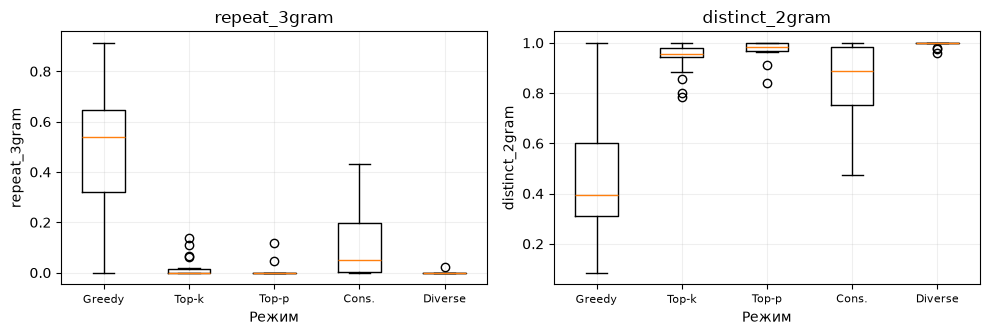

#### 2.5.4. Качественная оценка генерации

overall,Удачно,Частично удачно,Неудачно
Продолжений,1,21,68


,Начало,Язык,Тема и жанр,Связность,Стабильность
Средняя оценка (0–2),0.74,0.98,0.98,0.22,0.41


**Примеры лучших продолжений с переводом на русский**

In [11]:
profile("49m_400k")

#### 2.5.5. Анализ результатов

На 400 тыс. шагов достигнуты минимальный validation loss (3,1903) и perplexity (24,29) среди исследованных checkpoint. По фактам модель заняла первое место для эталона в 13 из 18 заданий, по контексту — в 4 из 18. Дополнительные 100 тыс. шагов снизили loss, но почти не изменили дискретные показатели Benchmark v3.

Средняя оценка генерации составила 0,67 против 0,73 на 300k; неудачными признаны 68 из 90 продолжений, полностью удачным — одно. Одновременно средняя повторяемость триграмм уменьшилась с 0,169 до 0,129 (раздел 3.4).

## 3. Глобальное сравнение

### 3.1. Общие показатели и ранги ответов

In [12]:
f=scores[scores.category=="facts"].groupby("model").agg(facts_top1=("top1","sum"),facts_mean_rank=("rank_sum","mean"))
c=scores[scores.category=="context"].groupby("model").agg(context_top1=("top1","sum"),context_control_top1=("control_top1","sum"),context_mean_rank_gain=("rank_gain","mean"),context_delta_logp=("delta_logp","mean"))
g=continuations.groupby("model").agg(repetition_3gram=("repeat_3gram","mean"),distinct_2gram=("distinct_2gram","mean"))
overview=training_summary.set_index(training_summary.model.map(lambda x:x.lower().replace('m / ','m_').replace(' ','')).rename('model'))
comparison=pd.concat([overview[["steps","val_loss","perplexity"]],f,c,g],axis=1).reindex(MODELS)
comparison["judge_good"] = judge_counts["Удачно"]
comparison["judge_mean_score"] = judge.groupby("model").mean_score.mean().reindex(MODELS)
display(comparison.rename(index=LABELS).round(3))

,steps,val_loss,perplexity,facts_top1,facts_mean_rank,context_top1,context_control_top1,context_mean_rank_gain,context_delta_logp,repetition_3gram,distinct_2gram,judge_good,judge_mean_score
model,,,,,,,,,,,,,
40M / 200k,200000,3.315,27.530,7,1.833,5,2.0,0.944,3.504,0.170,0.791,0,0.580
49M / 100k,100000,3.320,27.660,9,1.611,3,2.0,0.333,3.419,0.159,0.805,2,0.622
49M / 200k,200000,3.236,25.443,13,1.444,4,2.0,0.333,3.636,0.163,0.804,4,0.649
49M / 300k,300000,3.204,24.629,12,1.556,4,3.0,0.389,3.641,0.169,0.795,2,0.731
49M / 400k,400000,3.190,24.295,13,1.444,4,3.0,0.444,3.780,0.129,0.841,1,0.667


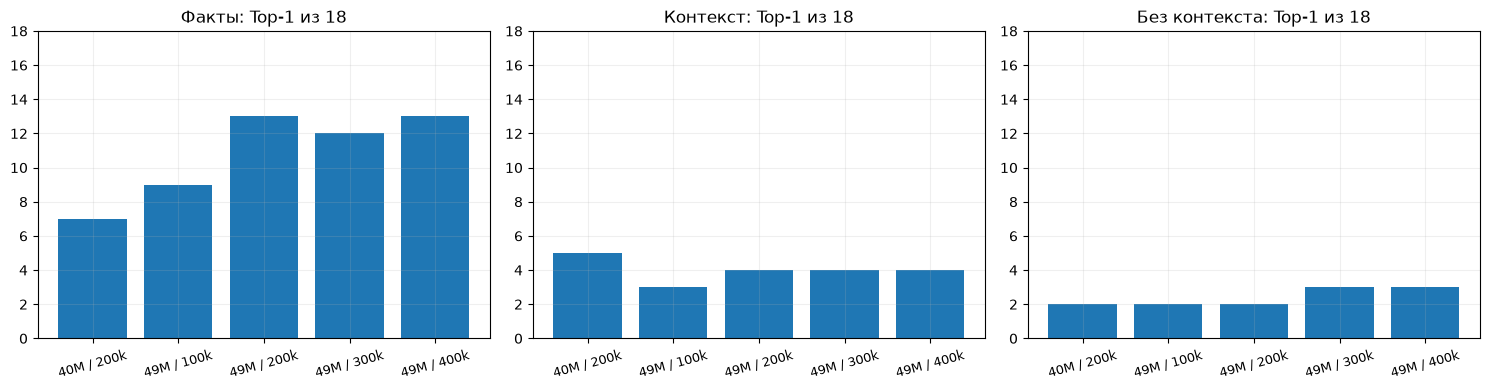

In [13]:
fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,col,title in zip(axes,["facts_top1","context_top1","context_control_top1"],["Факты: Top-1 из 18","Контекст: Top-1 из 18","Без контекста: Top-1 из 18"]):
    ax.bar(range(5),comparison[col]);ax.set(title=title,ylim=(0,18),xticks=range(5),xticklabels=list(LABELS.values()));ax.tick_params(axis="x",rotation=15,labelsize=9)
plt.tight_layout();plt.show()

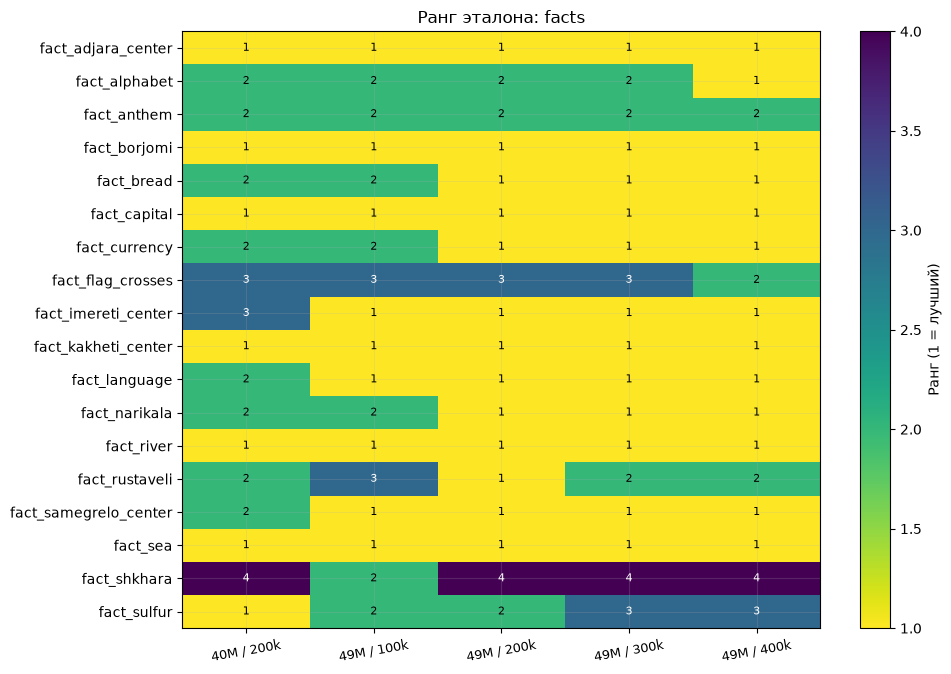

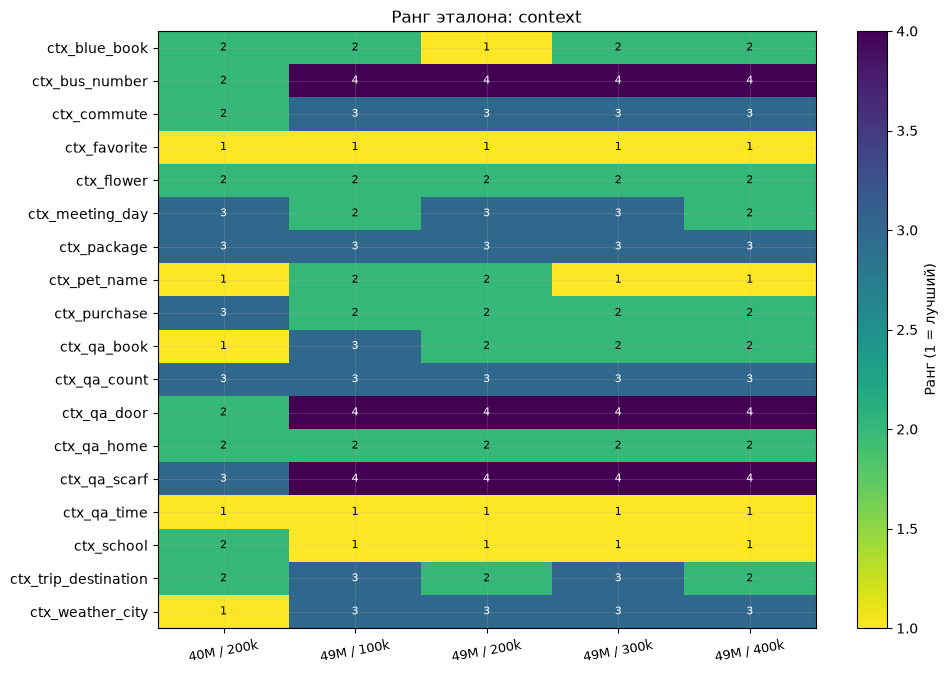

In [14]:
def heatmap_rank(category):
    x=scores[scores.category==category].pivot(index="id",columns="model",values="rank_sum").reindex(columns=MODELS)
    fig,ax=plt.subplots(figsize=(10, max(6,len(x)*.38)))
    im=ax.imshow(x.to_numpy(),aspect="auto",vmin=1,vmax=4,cmap="viridis_r")
    ax.set(xticks=range(len(MODELS)),xticklabels=list(LABELS.values()),yticks=range(len(x)),yticklabels=x.index,title=f"Ранг эталона: {category}")
    for (i,j),v in np.ndenumerate(x.to_numpy()):ax.text(j,i,str(int(v)),ha="center",va="center",fontsize=8,color="white" if v>2 else "black")
    ax.tick_params(axis="x", labelsize=9, rotation=10)
    plt.colorbar(im,ax=ax,label="Ранг (1 = лучший)");plt.tight_layout();plt.show()
heatmap_rank("facts")
heatmap_rank("context")

### 3.2. Что изменилось в конкретных заданиях между стадиями 49M

In [15]:
def transition(from_model,to_model,category):
    q=scores[scores.category==category].pivot(index="id",columns="model",values="rank_sum")
    before,after=q[from_model],q[to_model]
    tab=pd.DataFrame({"id":q.index,"before":before.to_numpy(),"after":after.to_numpy(),"change":(before-after).to_numpy()})
    display(Markdown(f"**{category}: {LABELS[from_model]} → {LABELS[to_model]}**"))
    display(pd.Series({"Улучшились":int((tab.change>0).sum()),"Не изменились":int((tab.change==0).sum()),"Ухудшились":int((tab.change<0).sum())}).to_frame("Заданий").T)
    display(tab.sort_values("change",ascending=False))
    display(pd.crosstab(before,after,rownames=["Ранг до"],colnames=["Ранг после"]))
transition("49m_100k","49m_400k","facts")
transition("49m_100k","49m_400k","context")

**facts: 49M / 100k → 49M / 400k**

,Улучшились,Не изменились,Ухудшились
Заданий,6,10,2


,id,before,after,change
1,fact_alphabet,2,1,1
4,fact_bread,2,1,1
13,fact_rustaveli,3,2,1
6,fact_currency,2,1,1
7,fact_flag_crosses,3,2,1
11,fact_narikala,2,1,1
0,fact_adjara_center,1,1,0
3,fact_borjomi,1,1,0
5,fact_capital,1,1,0
2,fact_anthem,2,2,0


Ранг после,1,2,3,4
Ранг до,,,,
1,9,0,0,0
2,4,1,1,1
3,0,2,0,0


**context: 49M / 100k → 49M / 400k**

,Улучшились,Не изменились,Ухудшились
Заданий,3,15,0


,id,before,after,change
7,ctx_pet_name,2,1,1
9,ctx_qa_book,3,2,1
16,ctx_trip_destination,3,2,1
0,ctx_blue_book,2,2,0
1,ctx_bus_number,4,4,0
2,ctx_commute,3,3,0
5,ctx_meeting_day,2,2,0
4,ctx_flower,2,2,0
6,ctx_package,3,3,0
3,ctx_favorite,1,1,0


Ранг после,1,2,3,4
Ранг до,,,,
1,3,0,0,0
2,1,5,0,0
3,0,2,4,0
4,0,0,0,3


### 3.3. Контекст: эффект дополнительной информации

top1  control_top1  improved_rank  worsened_rank  same_rank  \
model    format                                                                
40m_200k cloze      3           1.0              8              1          3   
         qa         2           1.0              4              0          2   
49m_100k cloze      2           1.0              3              0          9   
         qa         1           1.0              1              0          5   
49m_200k cloze      3           1.0              4              2          6   
         qa         1           1.0              2              1          3   
49m_300k cloze      3           2.0              4              2          6   
         qa         1           1.0              2              0          4   
49m_400k cloze      3           2.0              4              1          7   
         qa         1           1.0              2              0          4   

                 mean_delta_logp  
model    format                   
40m_200k cloze             3.820  
         qa                2.873  
49m_100k cloze             3.910  
         qa                2.438  
49m_200k cloze             4.206  
         qa                2.496  
49m_300k cloze             3.871  
         qa                3.182  
49m_400k cloze             4.177  
         qa                2.987

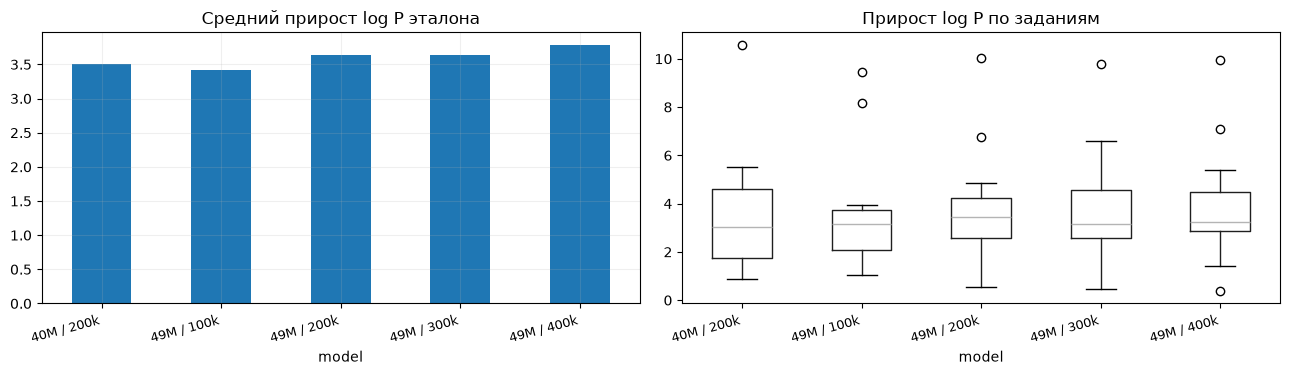

In [16]:
ctx=scores[scores.category=="context"]
display(ctx.groupby(["model","format"]).agg(top1=("top1","sum"),control_top1=("control_top1","sum"),improved_rank=("rank_gain",lambda s:int((s>0).sum())),worsened_rank=("rank_gain",lambda s:int((s<0).sum())),same_rank=("rank_gain",lambda s:int((s==0).sum())),mean_delta_logp=("delta_logp","mean")).round(3))
fig,axes=plt.subplots(1,2,figsize=(13,4))
ctx.groupby("model").delta_logp.mean().reindex(MODELS).plot.bar(ax=axes[0],title="Средний прирост log P эталона")
ctx.boxplot(column="delta_logp",by="model",ax=axes[1],grid=False)
axes[0].set_xticklabels([LABELS[m] for m in MODELS], rotation=15, ha="right", fontsize=9)
axes[1].set_xticklabels([LABELS[m] for m in MODELS], rotation=15, ha="right", fontsize=9)
axes[1].set_title("Прирост log P по заданиям")
fig.suptitle("")
plt.tight_layout();plt.show()

### 3.4. Сравнение режимов свободной генерации

,model,variant,mean_words,repeat_3gram,distinct_2gram
0,40m_200k,conservative,48.778,0.203,0.729
1,40m_200k,diverse,47.778,0.000,0.996
2,40m_200k,greedy,51.611,0.605,0.352
3,40m_200k,topk_t08,52.944,0.017,0.939
4,40m_200k,topp_t08,49.278,0.028,0.940
5,49m_100k,conservative,50.611,0.104,0.824
6,49m_100k,diverse,48.778,0.000,0.999
7,49m_100k,greedy,54.833,0.661,0.297
8,49m_100k,topk_t08,48.278,0.026,0.934
9,49m_100k,topp_t08,52.222,0.007,0.971


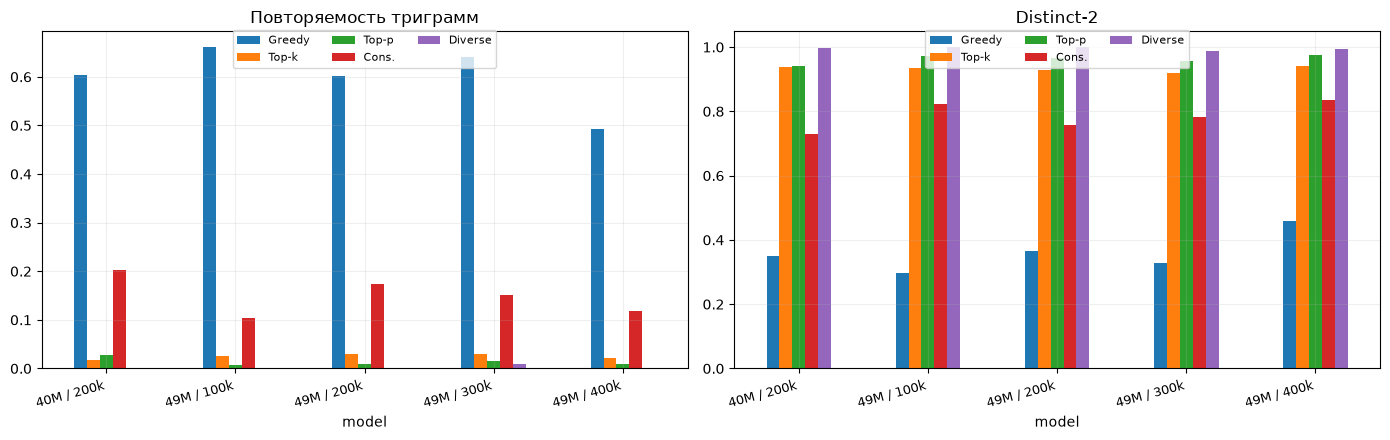

In [17]:
generation_comparison=continuations.groupby(["model","variant"]).agg(mean_words=("word_count","mean"),repeat_3gram=("repeat_3gram","mean"),distinct_2gram=("distinct_2gram","mean")).reset_index()
display(generation_comparison.round(3))
fig,axes=plt.subplots(1,2,figsize=(14,4.5))
for ax,key,title in zip(axes,["repeat_3gram","distinct_2gram"],["Повторяемость триграмм","Distinct-2"]):
    pivot=generation_comparison.pivot(index="model",columns="variant",values=key).reindex(index=MODELS,columns=MODES)
    pivot.rename(index=LABELS).plot.bar(ax=ax,title=title)
    ax.tick_params(axis="x",rotation=15,labelsize=9)
    ax.set_xticklabels(list(LABELS.values()), ha="right")
    handles, _ = ax.get_legend_handles_labels()
    ax.legend(handles, ["Greedy", "Top-k", "Top-p", "Cons.", "Diverse"], fontsize=8, loc="upper center", bbox_to_anchor=(.5, 1.02), ncol=3)
plt.tight_layout();plt.show()

### 3.5. Качественная оценка продолжений

overall,Удачно,Частично удачно,Неудачно,Средняя оценка (0–2)
model,,,,
40M / 200k,0,19,71,0.58
49M / 100k,2,23,65,0.62
49M / 200k,4,16,70,0.65
49M / 300k,2,26,62,0.73
49M / 400k,1,21,68,0.67


,Начало,Язык,Тема и жанр,Связность,Стабильность
model,,,,,
40M / 200k,0.61,0.89,0.98,0.13,0.29
49M / 100k,0.67,0.89,1.02,0.20,0.33
49M / 200k,0.70,0.98,1.00,0.23,0.33
49M / 300k,0.86,1.06,1.08,0.24,0.42
49M / 400k,0.74,0.98,0.98,0.22,0.41


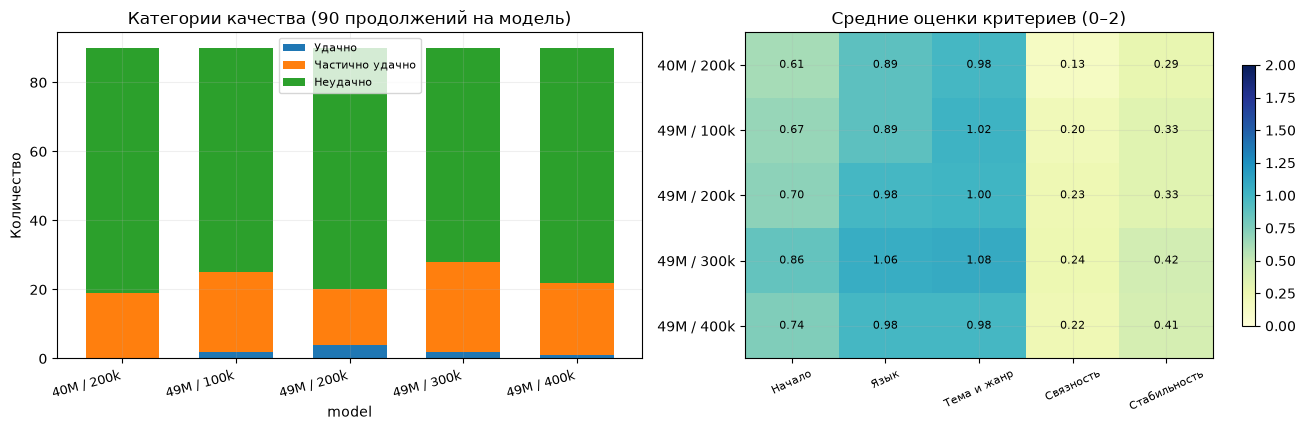

overall,Удачно,Частично удачно,Неудачно
variant,,,
Greedy,1,34,55
Top-k,4,23,63
Top-p,2,24,64
Conservative,1,20,69
Diverse,1,4,85


In [18]:
quality_summary = judge_counts.copy()
quality_summary["Средняя оценка (0–2)"] = judge.groupby("model").mean_score.mean().reindex(MODELS)
display(quality_summary.rename(index=LABELS).round(2))

display(judge_criteria.rename(index=LABELS, columns=dict(zip(JUDGE_CRITERIA, JUDGE_LABELS))).round(2))

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.4))
judge_counts.rename(index=LABELS).plot.bar(stacked=True, ax=axes[0], width=.65)
axes[0].set(title="Категории качества (90 продолжений на модель)", ylabel="Количество")
axes[0].set_xticklabels(list(LABELS.values()), rotation=15, ha="right", fontsize=9)
axes[0].legend(fontsize=8)

values = judge_criteria.to_numpy()
im = axes[1].imshow(values, vmin=0, vmax=2, aspect="auto", cmap="YlGnBu")
axes[1].set(xticks=range(5), xticklabels=JUDGE_LABELS,
            yticks=range(5), yticklabels=list(LABELS.values()),
            title="Средние оценки критериев (0–2)")
axes[1].tick_params(axis="x", rotation=25, labelsize=8)
for (i, j), v in np.ndenumerate(values):
    axes[1].text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                 color="white" if v > 1.2 else "black")
fig.colorbar(im, ax=axes[1], shrink=.8)
plt.tight_layout(); plt.show()

mode_quality = pd.crosstab(judge.variant, judge.overall).reindex(index=MODES, columns=JUDGE_CATEGORIES, fill_value=0)
display(mode_quality.rename(index=dict(zip(MODES, ["Greedy", "Top-k", "Top-p", "Conservative", "Diverse"]))))

### 3.6. Сопоставление текстов на одном промпте

Выберите идентификатор задания и режим. Все пять реальных продолжений будут показаны вместе.

In [19]:
def show_generations(task_id, variant):
    from html import escape
    from IPython.display import HTML

    x = generations[(generations.id == task_id) & (generations.variant == variant)].set_index("model").reindex(MODELS)
    prompt = str(x.prompt.dropna().iloc[0])
    display(HTML("<strong>Промпт</strong><div style='white-space:pre-wrap; margin:.5em 0 1em'>" + escape(prompt) + "</div>"))
    for m, row in x.iterrows():
        response = str(row.response)
        display(HTML("<strong>" + escape(LABELS[m]) + "</strong><div style='white-space:pre-wrap; margin:.35em 0 1em'>" + escape(response) + "</div>"))

try:
    import ipywidgets as widgets
except ImportError:
    print("python -m pip install ipywidgets")
    show_generations("cont_family_letter", "greedy")
else:
    tasks = generations.drop_duplicates("id").sort_values("id")
    task_options = [
        (f"{r.id} · {r.category} · {str(r.prompt)[:55]}", r.id)
        for r in tasks.itertuples()
    ]
    task_ids = [value for _, value in task_options]
    selected_task = "cont_family_letter" if "cont_family_letter" in task_ids else task_ids[0]
    task_selector = widgets.Dropdown(
        options=task_options, value=selected_task, description="Задание:",
        layout=widgets.Layout(width="72%"), style={"description_width": "initial"}
    )
    mode_selector = widgets.Dropdown(
        options=MODES, value="greedy", description="Режим:",
        layout=widgets.Layout(width="25%"), style={"description_width": "initial"}
    )
    output = widgets.interactive_output(
        show_generations, {"task_id": task_selector, "variant": mode_selector}
    )
    display(widgets.VBox([widgets.HBox([task_selector, mode_selector]), output]))

### 3.7. Влияние числа шагов: только 49M

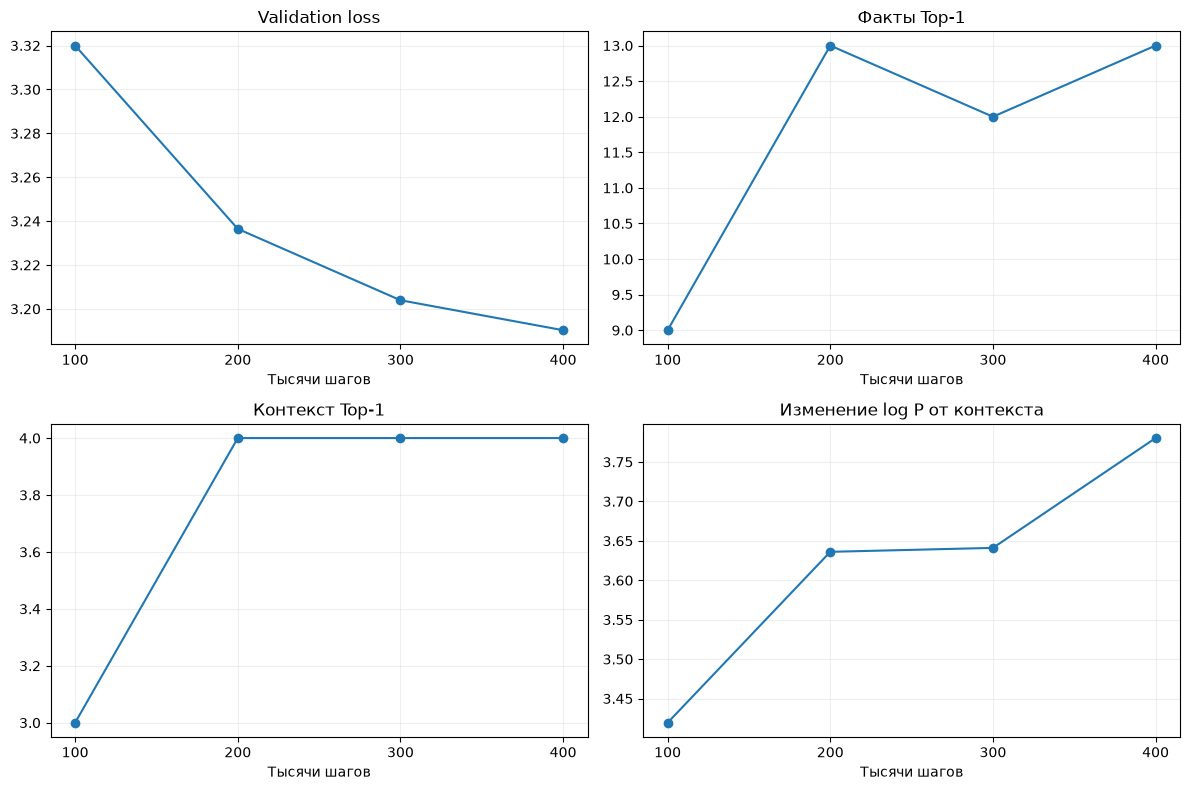

,val_loss,perplexity,facts_top1,facts_mean_rank,context_top1,context_control_top1,context_mean_rank_gain,context_delta_logp,repetition_3gram,distinct_2gram,judge_good,judge_mean_score
steps,,,,,,,,,,,,
100000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
200000,-0.0835,-2.2167,4.0,-0.1667,1.0,0.0,0.0000,0.2166,0.0035,-0.0015,2.0,0.0267
300000,-0.0325,-0.8143,-1.0,0.1111,0.0,1.0,0.0556,0.0050,0.0060,-0.0084,-2.0,0.0822
400000,-0.0137,-0.3343,1.0,-0.1111,0.0,0.0,0.0556,0.1392,-0.0402,0.0460,-1.0,-0.0644


In [20]:
x=comparison.loc[["49m_100k","49m_200k","49m_300k","49m_400k"]].set_index("steps")
fig,axes=plt.subplots(2,2,figsize=(12,8))
for ax,key,title in zip(axes.flat,["val_loss","facts_top1","context_top1","context_delta_logp"],["Validation loss","Факты Top-1","Контекст Top-1","Изменение log P от контекста"]):
    ax.plot(x.index / 1000,x[key],marker="o");ax.set(title=title,xlabel="Тысячи шагов",xticks=[100,200,300,400])
plt.tight_layout();plt.show()
display(x.diff().round(4))

### 3.8. Влияние размера: 40M/200k против 49M/200k

Сопоставление двух независимых запусков на одинаковом количестве шагов. Без нескольких seed выводы ограничены данными конкретными экспериментами.

In [21]:
pair=comparison.loc[["40m_200k","49m_200k"]].T
pair.columns=[LABELS[m] for m in ["40m_200k","49m_200k"]]
pair["49M − 40M"]=pair.iloc[:,1]-pair.iloc[:,0]
display(pair.round(4))
for category in ("facts","context"):
    transition("40m_200k","49m_200k",category)

,40M / 200k,49M / 200k,49M − 40M
steps,200000.0000,200000.0000,0.0000
val_loss,3.3153,3.2365,-0.0788
perplexity,27.5296,25.4435,-2.0861
facts_top1,7.0000,13.0000,6.0000
facts_mean_rank,1.8333,1.4444,-0.3889
context_top1,5.0000,4.0000,-1.0000
context_control_top1,2.0000,2.0000,0.0000
context_mean_rank_gain,0.9444,0.3333,-0.6111
context_delta_logp,3.5039,3.6360,0.1321
repetition_3gram,0.1704,0.1629,-0.0075


**facts: 40M / 200k → 49M / 200k**

,Улучшились,Не изменились,Ухудшились
Заданий,7,10,1


,id,before,after,change
8,fact_imereti_center,3,1,2
4,fact_bread,2,1,1
14,fact_samegrelo_center,2,1,1
13,fact_rustaveli,2,1,1
6,fact_currency,2,1,1
10,fact_language,2,1,1
11,fact_narikala,2,1,1
0,fact_adjara_center,1,1,0
1,fact_alphabet,2,2,0
2,fact_anthem,2,2,0


Ранг после,1,2,3,4
Ранг до,,,,
1,6,1,0,0
2,6,2,0,0
3,1,0,1,0
4,0,0,0,1


**context: 40M / 200k → 49M / 200k**

,Улучшились,Не изменились,Ухудшились
Заданий,3,8,7


,id,before,after,change
0,ctx_blue_book,2,1,1
8,ctx_purchase,3,2,1
15,ctx_school,2,1,1
16,ctx_trip_destination,2,2,0
5,ctx_meeting_day,3,3,0
3,ctx_favorite,1,1,0
6,ctx_package,3,3,0
14,ctx_qa_time,1,1,0
10,ctx_qa_count,3,3,0
4,ctx_flower,2,2,0


Ранг после,1,2,3,4
Ранг до,,,,
1,2,2,1,0
2,2,3,1,2
3,0,1,3,1


### 3.9. Обобщение сравнительных результатов

Сопоставление по числу шагов (раздел 3.7) выявило различную динамику показателей. Для 49M снижение validation loss между 100k и 400k сопровождалось улучшением результата на фактах с 9 до 13 правильных первых мест из 18. При этом после 200k фактическая accuracy колебалась в пределах 12–13 ответов, а задания с контекстом оставались на уровне 4 из 18. По изменениям рангов (раздел 3.2) прогресс был неравномерным: часть вопросов улучшилась, но большинство сохранило прежние позиции. Небольшой объём тестов ограничивает точность этих сравнений.

Контроль без контекста (раздел 3.3) позволяет отделить изменение предпочтения ответа от его абсолютной вероятности. Для всех моделей дополнительный контекст в среднем повышал суммарную log-probability эталона, но нередко не выводил его на первое место. У 40M/200k улучшение ранга выражено сильнее, чем у 49M, несмотря на более высокий validation loss. Вероятный источник расхождения — различная чувствительность моделей к конкретным формулировкам и альтернативам заданий.

Качественные оценки (раздел 3.5) не повторяют монотонную динамику loss: максимальный средний балл принадлежит 49M/300k (0,73), тогда как 49M/400k имеет меньший loss, но более низкий балл судьи (0,67). Кроме того, высокий Distinct-2 не равнозначен связному тексту: режим diverse почти не повторяет биграммы, но 85 из 90 его продолжений признаны неудачными. Greedy чаще сохраняет правильное начало и получает самый высокий средний балл по критериям среди режимов (0,84), однако демонстрирует сильную механическую повторяемость и минимальную стабильность (0,04). Режимы Top-k и Top-p обеспечивают более низкую повторяемость; первый дал больше полностью удачных текстов (4 против 2), второй — более высокую оценку стабильности (0,74 против 0,47). 

Сравнение архитектур при 200k (раздел 3.8) показывает преимущество 49M в validation loss (3,2365 против 3,3153), ранжировании фактов (13/18 против 7/18) и среднем балле судьи (0,65 против 0,58), но не в Top-1 для контекстных заданий (4/18 против 5/18).

## 4. Итоговые результаты

### 4.1. Сводная таблица и экспорт

In [22]:
display(comparison.rename(index=LABELS).round(3))
SAVE_TABLES = True
if SAVE_TABLES:
    tables=EXPORT / "tables"
    tables.mkdir(parents=True,exist_ok=True)
    comparison.to_csv(tables / "comparison_summary.csv",encoding="utf-8-sig")
    training_summary.to_csv(tables / "training_summary.csv",index=False,encoding="utf-8-sig")
    scores.to_csv(tables / "per_question_scores.csv",index=False,encoding="utf-8-sig")
    generation_comparison.to_csv(tables / "generation_metrics.csv",index=False,encoding="utf-8-sig")
    judge.to_csv(tables / "judge_per_generation.csv", index=False, encoding="utf-8-sig")
    judge_counts.to_csv(tables / "judge_category_counts.csv", encoding="utf-8-sig")
    judge_criteria.to_csv(tables / "judge_criteria_means.csv", encoding="utf-8-sig")
    print("Таблицы сохранены:",tables)

,steps,val_loss,perplexity,facts_top1,facts_mean_rank,context_top1,context_control_top1,context_mean_rank_gain,context_delta_logp,repetition_3gram,distinct_2gram,judge_good,judge_mean_score
model,,,,,,,,,,,,,
40M / 200k,200000,3.315,27.530,7,1.833,5,2.0,0.944,3.504,0.170,0.791,0,0.580
49M / 100k,100000,3.320,27.660,9,1.611,3,2.0,0.333,3.419,0.159,0.805,2,0.622
49M / 200k,200000,3.236,25.443,13,1.444,4,2.0,0.333,3.636,0.163,0.804,4,0.649
49M / 300k,300000,3.204,24.629,12,1.556,4,3.0,0.389,3.641,0.169,0.795,2,0.731
49M / 400k,400000,3.190,24.295,13,1.444,4,3.0,0.444,3.780,0.129,0.841,1,0.667


Таблицы сохранены: /home/daneque/projects/GGPT/reports/comparison/tables


### 4.2. Выбор модели и режима генерации

Для последующего инференса выбрана модель 49M/300k с режимом `topk_t08` (Top-k, температура 0,8). Основание для выбора модели — лучший средний балл качественной оценки среди пяти checkpoint (0,73 из 2) и наименьшая доля неудачных продолжений (62 из 90). По фактическим заданиям результат 12/18 близок к максимуму 13/18, а разница с 49M/400k по loss невелика (3,2039 против 3,1903).